# Verificação e Validação — Predição de Carga Alta (EVCOMX)

Segue a **Aula 07 do bootcamp** (Verificação e Validação de Modelos) e o Guia de Modelagem da
EVCOMX (§6). A aula separa duas perguntas:
- **Verificação:** o modelo foi construído e executado como dissemos?
- **Validação:** ele funciona em dados novos, e dá para confiar nele fora do conjunto original?

**Modelo verificado: o oficial**, a média de 5 Gradient Boosting com 121 features (120 + o
resultado do cestão 1), de `src/selecao_algoritmos/modelo_final.joblib`. A verificação da RF de 6
features (o antigo plano A) está guardada no histórico do Git.

**Esta etapa não escolhe nada.** O script **para com erro** se algum número das etapas anteriores
não bater.

| Seção | Slide / Guia |
|---|---|
| 1. Checklist técnico (rótulos, pipeline, transformações, vazamento, métricas, reprodução, baseline, Guia §6.1) | slide 8 |
| 2. Gap treino × walk-forward × validação × teste; complexidade | slides 10 a 12 |
| 3. O teste não é uma segunda validação | slides 15 e 29 |
| 4. Tipos de validação cruzada | slide 27 |
| 5. Drift dos dados e do conceito; walk-forward; robustez; corte de peso; sementes | slides 33–34, Guia §6.2 |
| 6. Critérios de aceitação, monitoramento, validação de domínio e de negócio | slides 34–35, Guia §6.3–6.4 |
| 7. Registro do experimento | slide 30 |
| 8. Conclusão | slides 37–38 |

**Rode antes** a feature selection, a seleção de algoritmos e a análise de modelos. Leva ~10 min.

In [1]:
import hashlib
import json
import platform
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from sklearn.metrics import average_precision_score, confusion_matrix, roc_auc_score
from sklearn.model_selection import GroupKFold, StratifiedKFold

warnings.filterwarnings("ignore")
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "comum").is_dir())
sys.path.insert(0, str(RAIZ))
from comum.protocolo import (ARQ_COMPLETO, ARQ_DATASET, C_FP, HGB, MESES_CUSTO, MESES_WF, NOME_OFICIAL, NOME_REGRA,
                             NOME_RESERVA, NOME_RF6, VARIANTES, carregar, familia, ler_features, melhor_limiar,
                             minutos, oof_dev, prever, prever_treinados, resumo_wf, treinar)

PASTA = RAIZ / "src" / "verificacao_validacao"
(PASTA / "graficos").mkdir(exist_ok=True)
SEL, ANA = RAIZ / "src" / "selecao_algoritmos", RAIZ / "src" / "analise_modelos"
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.6, "axes.axisbelow": True})
AZUL, VERMELHO, CINZA, LARANJA, VERDE = "#2b6cb0", "#c0392b", "#7f8c8d", "#dd8a2e", "#4a8c4a"

## 0. Ler os arquivos das etapas anteriores

In [2]:
FEAT = ler_features(); F_OF = FEAT["features_oficial"]; F_PR = FEAT["features_principal"]; GRUPOS = FEAT["grupos"]
D, DEV, TESTE = carregar(ARQ_COMPLETO)
TREINO, VALID = DEV[DEV.conjunto == "treino"], DEV[DEV.conjunto == "validacao"]
PREV = pd.read_csv(SEL / "previsoes_dev_teste.csv")
RES = pd.read_csv(SEL / "resultado_teste.csv", index_col=0)
PAC = joblib.load(SEL / "modelo_final.joblib"); PDEV = joblib.load(SEL / "modelo_dev.joblib")
resp = pd.read_csv(RAIZ / "original_dataset/VariavelResposta.csv")
base = pd.read_csv(RAIZ / "src/EDA/base.csv", dtype={"cd_codigo_material": str})
bruto = pd.read_csv(RAIZ / "original_dataset/infos_camadas.csv", dtype={"cd_codigo_material": str})
chave = ["cd_corrida", "nu_carregamento"]
LIM = RES.loc[NOME_OFICIAL, "limiar"]
SEM_TESTE = TESTE.min_parada.sum()
print(f"dev {DEV.shape} | teste {TESTE.shape} | limiar do dev {LIM:.4f} | sklearn {sklearn.__version__}")

CHECK = []


def ic(txt):
    """'[-75.1 -7.7]' (como o CSV guarda um array) → (-75.1, -7.7)"""
    import re
    v = [float(x) for x in re.findall(r"-?\d+\.?\d*", str(txt))]
    return v[0], v[-1]


def conferir(item, descricao, ok, detalhe="", ressalva=False):
    status = "OK" if ok and not ressalva else ("RESSALVA" if ok else "FALHA")
    CHECK.append({"item": item, "conferencia": descricao, "status": status, "detalhe": detalhe})
    print(f"[{status:8s}] {item} {descricao} {('— ' + detalhe) if detalhe else ''}")
    if not ok:
        raise AssertionError(f"{item}: {descricao} — {detalhe}")

dev (2986, 140) | teste (515, 140) | limiar do dev 0.1784 | sklearn 1.9.1


## 1. Checklist técnico antes de confiar nos números (slide 8)

### 1.1 Os rótulos e as classes estão corretos?

In [3]:
alvo = pd.concat([resp.assign(nu_carregamento=1.0, y=resp.is_carga_alta_carregamento_1),
                  resp.assign(nu_carregamento=2.0, y=resp.is_carga_alta_carregamento_2)])[chave + ["y"]]
m = D.merge(alvo, on=chave, how="left")
conferir("1.1a", "carga_alta = arquivo bruto da EVCOMX, cestão a cestão", (m.carga_alta == m.y).all(),
         f"{len(m)} cestões, {int(m.carga_alta.sum())} cargas altas ({m.carga_alta.mean():.1%})")
c1 = D[D.nu_carregamento == 1].set_index("cd_corrida")["carga_alta"]
c2 = D[D.nu_carregamento == 2]
conferir("1.1b", "carga_alta_c1 = resultado do cestão 1 da mesma corrida (no cestão 2) e 0 no cestão 1",
         (c2.carga_alta_c1.values == c2.cd_corrida.map(c1).values).all() and (D[D.nu_carregamento == 1].carga_alta_c1 == 0).all())
conferir("1.1c", "min_parada > 0 só quando há carga alta", ((D.min_parada > 0) <= (D.carga_alta == 1)).all(),
         f"parada média {D[D.carga_alta == 1].min_parada.mean():.1f} min")

[OK      ] 1.1a carga_alta = arquivo bruto da EVCOMX, cestão a cestão — 3501 cestões, 559 cargas altas (16.0%)
[OK      ] 1.1b carga_alta_c1 = resultado do cestão 1 da mesma corrida (no cestão 2) e 0 no cestão 1 
[OK      ] 1.1c min_parada > 0 só quando há carga alta — parada média 3.9 min


### 1.2 Treino, validação e teste passaram pelo mesmo pipeline?

In [4]:
dm = pd.read_csv(ARQ_DATASET)
conferir("1.2a", "dataset_modelagem_fs.csv = mesmas linhas e valores do dataset completo, nas 121 features",
         dm.set_index(chave)[F_OF].sort_index().equals(D.set_index(chave)[F_OF].sort_index()) or
         np.allclose(dm.set_index(chave)[F_OF].sort_index().fillna(-999).values.astype(float),
                     D.set_index(chave)[F_OF].sort_index().fillna(-999).values.astype(float)))
conferir("1.2b", "as 3 partições têm as mesmas colunas e nenhuma feature inteira vazia",
         all(D[D.conjunto == c][F_OF].notna().any().all() for c in ["treino", "validacao", "teste"]))
conferir("1.2c", "o pacote de uso tem as 121 features na mesma ordem do JSON", PAC["com_cestao1"]["features"] == F_OF)

[OK      ] 1.2a dataset_modelagem_fs.csv = mesmas linhas e valores do dataset completo, nas 121 features 
[OK      ] 1.2b as 3 partições têm as mesmas colunas e nenhuma feature inteira vazia 
[OK      ] 1.2c o pacote de uso tem as 121 features na mesma ordem do JSON 


### 1.3 As transformações usam só o passado?

Com Gradient Boosting não há imputação nem padronização ajustadas nos dados (o HGB lida com
vazios). O risco está nas features que olham para trás: o histórico, o regime recente (`rel_`) e
o walk-forward.

In [5]:
ordem = resp.merge(D[D.nu_carregamento == 1][["cd_corrida", "t_ini"]], on="cd_corrida").sort_values("t_ini")
h5 = ordem.is_carga_alta.shift(1).rolling(5, min_periods=1).mean()
mm = D[D.nu_carregamento == 1].set_index("cd_corrida")["h_taxa5"]
conferir("1.3a", "h_taxa5 recalculado do bruto com shift(1) = dataset (nunca a corrida atual)",
         np.allclose(h5.values, ordem.cd_corrida.map(mm).values, equal_nan=True))
conferir("1.3b", "taxa_ca_ult5 (da rodada RF) = h_taxa5 (mesma conta)", np.allclose(D.taxa_ca_ult5, D.h_taxa5, equal_nan=True))
s = D.sort_values("t_ini").reset_index(drop=True)
rel = s.densidade_media - s.densidade_media.shift(1).rolling(100, min_periods=20).mean()
conferir("1.3c", "rel_densidade_media = valor − média dos 100 cestões ANTERIORES", np.allclose(rel, s.rel_densidade_media, equal_nan=True))
viz = []
for mth in MESES_WF:
    ini = DEV[DEV.mes == mth].t_ini.min()
    viz.append((DEV.t_ini < ini).sum() and (DEV[DEV.t_ini < ini].t_ini.max() < ini))
conferir("1.3d", "walk-forward: cada mês treina só com cestões que começaram antes dele", all(viz))
lim_corr = D.groupby("conjunto").t_ini.agg(["min", "max"])
cruz = int(((D.conjunto == "treino") & (D.t_ini > lim_corr.loc["validacao", "min"])).sum()
           + ((D.conjunto == "validacao") & (D.t_ini > lim_corr.loc["teste", "min"])).sum())
conferir("1.3e", "split temporal por corrida sem sobreposição", True,
         f"{cruz} cestões 2 com hora registrada depois do início da partição seguinte (dado, não modelo)",
         ressalva=cruz > 0)

[OK      ] 1.3a h_taxa5 recalculado do bruto com shift(1) = dataset (nunca a corrida atual) 
[OK      ] 1.3b taxa_ca_ult5 (da rodada RF) = h_taxa5 (mesma conta) 
[OK      ] 1.3c rel_densidade_media = valor − média dos 100 cestões ANTERIORES 
[OK      ] 1.3d walk-forward: cada mês treina só com cestões que começaram antes dele 
[RESSALVA] 1.3e split temporal por corrida sem sobreposição — 2 cestões 2 com hora registrada depois do início da partição seguinte (dado, não modelo)


### 1.4 Há vazamento de dados? (slides 19 e 20)

In [6]:
conferir("1.4a", "duração da parada e alvo não são features",
         not {"min_parada", "carga_alta", "segundos_parada", "qt_segundos_parada_carga_alta"} & set(F_OF))
def _sinal(c):
    r = TREINO[c].corr(TREINO.carga_alta)
    return 1.0 if not np.isfinite(r) or r == 0 else np.sign(r)


pr_sozinha = {c: average_precision_score(TREINO.carga_alta, TREINO[c].fillna(TREINO[c].median()) * _sinal(c)) for c in F_OF}
top = max(pr_sozinha, key=pr_sozinha.get)
conferir("1.4b", "nenhuma feature sozinha é 'boa demais' (PR-AUC isolada no treino < 0,6)", pr_sozinha[top] < 0.6,
         f"a melhor é {top} ({pr_sozinha[top]:.2f}; chute {TREINO.carga_alta.mean():.2f})")
conferir("1.4c", "carga_alta_c1: timing confirmado pela EVCOMX (31/out/2026); no cestão 1 vale 0", True,
         "se o resultado do cestão 1 faltar, o app usa a reserva sem ele", ressalva=True)
# o que um vazamento de verdade faria: histórico incluindo a corrida atual
vaz = DEV.copy()
cur = resp.set_index("cd_corrida").is_carga_alta
vaz["h_ult1"] = vaz.cd_corrida.map(cur)
pv_vaz = prever(familia(F_OF), vaz[vaz.conjunto == "treino"], vaz[vaz.conjunto == "validacao"])
pv_ok = prever(familia(F_OF), TREINO, VALID)
print(f"   Demonstração: se 'h_ult1' fosse a corrida ATUAL (vazamento), a PR-AUC na validação iria de "
      f"{average_precision_score(VALID.carga_alta, pv_ok):.3f} para {average_precision_score(VALID.carga_alta, pv_vaz):.3f}")

[OK      ] 1.4a duração da parada e alvo não são features 
[OK      ] 1.4b nenhuma feature sozinha é 'boa demais' (PR-AUC isolada no treino < 0,6) — a melhor é rel_prop_peso_pesado (0.35; chute 0.16)
[RESSALVA] 1.4c carga_alta_c1: timing confirmado pela EVCOMX (31/out/2026); no cestão 1 vale 0 — se o resultado do cestão 1 faltar, o app usa a reserva sem ele
   Demonstração: se 'h_ult1' fosse a corrida ATUAL (vazamento), a PR-AUC na validação iria de 0.450 para 0.881


### 1.5 As métricas correspondem ao objetivo? (conta à mão)

In [7]:
pt = PREV[(PREV.modelo == NOME_OFICIAL) & (PREV.parte == "teste")].set_index(chave).loc[TESTE.set_index(chave).index]
a = pt.p.values > LIM; y = TESTE.carga_alta.values.astype(bool)
tn, fp, fn, tp = confusion_matrix(y, a).ravel()
mao = TESTE.min_parada.values[y & ~a].sum() + fp * C_FP
conferir("1.5a", "minutos do teste à mão (Σ paradas dos FN + 1 × FP) = resultado_teste.csv",
         np.isclose(mao, RES.loc[NOME_OFICIAL, "min perdidos teste"]), f"{mao:.1f} min = {fn} FN + {fp} FP")
conferir("1.5b", "recall, precisão e alarmes à mão = resultado_teste.csv",
         np.isclose(tp / (tp + fn), RES.loc[NOME_OFICIAL, "recall"]) and np.isclose(tp / (tp + fp), RES.loc[NOME_OFICIAL, "precisão"]))
pos = np.sort(pt.p.values[y])[::-1]
ap_mao = np.mean([(pt.p.values >= v).sum() and ((pt.p.values >= v) & y).sum() / (pt.p.values >= v).sum() for v in pos])
conferir("1.5c", "PR-AUC (average precision) à mão = sklearn", np.isclose(ap_mao, RES.loc[NOME_OFICIAL, "PR-AUC teste"], atol=1e-9),
         f"{ap_mao:.4f}")

[OK      ] 1.5a minutos do teste à mão (Σ paradas dos FN + 1 × FP) = resultado_teste.csv — 130.8 min = 18 FN + 91 FP
[OK      ] 1.5b recall, precisão e alarmes à mão = resultado_teste.csv 
[OK      ] 1.5c PR-AUC (average precision) à mão = sklearn — 0.5670


### 1.6 O experimento pode ser reproduzido?

In [8]:
p_re = prever(familia(F_OF), DEV, TESTE)
conferir("1.6a", "re-treinar o oficial no dev dá exatamente as chances salvas pela seleção", np.allclose(p_re, pt.p.values, atol=1e-12))
p_dev = np.mean([mm_.predict_proba(TESTE[F_OF])[:, 1] for mm_ in PDEV["modelos"]], axis=0)
conferir("1.6b", "modelo_dev.joblib = mesmas chances", np.allclose(p_dev, p_re, atol=1e-12))
TUDO = pd.concat([DEV, TESTE], ignore_index=True)
p_uso = np.mean([mm_.predict_proba(TUDO[F_OF])[:, 1] for mm_ in PAC["com_cestao1"]["modelos"]], axis=0)
p_uso2 = prever(familia(F_OF), TUDO, TUDO)
conferir("1.6c", "modelo_final.joblib (todos os dados) = re-treino com a mesma receita", np.allclose(p_uso, p_uso2, atol=1e-12))
conferir("1.6d", "versões: scikit-learn do pacote = do ambiente", PAC["versao_sklearn"] == sklearn.__version__, sklearn.__version__)

[OK      ] 1.6a re-treinar o oficial no dev dá exatamente as chances salvas pela seleção 
[OK      ] 1.6b modelo_dev.joblib = mesmas chances 
[OK      ] 1.6c modelo_final.joblib (todos os dados) = re-treino com a mesma receita 
[OK      ] 1.6d versões: scikit-learn do pacote = do ambiente — 1.9.1


### 1.7 Os resultados são coerentes com uma baseline? (slide 31)

In [9]:
boot = pd.read_csv(ANA / "bootstrap_teste.csv")
b = boot[(boot.modelo.str.startswith("OFICIAL")) & (boot.contra.str.startswith("Regra"))].iloc[0]
conferir("1.7a", "oficial < sem modelo nos minutos (teste e dev)",
         RES.loc[NOME_OFICIAL, "min perdidos teste"] < SEM_TESTE, f"{RES.loc[NOME_OFICIAL, 'min perdidos teste']:.0f} × {SEM_TESTE:.0f} min")
conferir("1.7b", "oficial × regra do histórico no teste (bootstrap por dia)", True,
         f"dif. minutos {b['dif minutos']:+.0f} (IC90 {b['IC90 minutos']}); dif. PR-AUC {b['dif PR-AUC']:+.3f} (IC90 {b['IC90 PR-AUC']})",
         ressalva=ic(b["IC90 minutos"])[1] >= 0)

[OK      ] 1.7a oficial < sem modelo nos minutos (teste e dev) — 131 × 251 min
[RESSALVA] 1.7b oficial × regra do histórico no teste (bootstrap por dia) — dif. minutos -17 (IC90 [-59.1  20.5]); dif. PR-AUC +0.212 (IC90 [0.105 0.315])


### 1.8 Verificação técnica do Guia de Modelagem (§6.1)

- **1.8a Teste de sanidade:** embaralhar o alvo do treino. Se o pipeline não vaza, a PR-AUC na
  validação cai para o nível do chute.
- **1.8b Testes da agregação** camada → cestão.
- **1.8c Joins:** quantos cestões e corridas em cada etapa.

In [10]:
rng = np.random.default_rng(0); emb = []
for i in range(5):
    tr = TREINO.copy(); tr["carga_alta"] = rng.permutation(tr.carga_alta.values)
    emb.append(average_precision_score(VALID.carga_alta, prever(familia(F_OF), tr, VALID)))
conferir("1.8a", "alvo embaralhado → PR-AUC no nível do chute", np.mean(emb) < VALID.carga_alta.mean() + 0.05,
         f"{np.mean(emb):.3f} (de {min(emb):.3f} a {max(emb):.3f}); chute {VALID.carga_alta.mean():.3f}; modelo real {average_precision_score(VALID.carga_alta, pv_ok):.3f}")
bb = base[base.nu_carregamento.isin([1, 2])]
agg = bb.groupby(chave).agg(peso=("peso_t", "sum"), vol=("volume_m3", "sum"))
cmp_ = D.set_index(chave)[["peso_t_total", "volume_m3_total"]].join(agg)
conferir("1.8b", "peso e volume do cestão = soma das camadas", np.allclose(cmp_.peso_t_total, cmp_.peso) and np.allclose(cmp_.volume_m3_total, cmp_.vol))
conferir("1.8b", "leve + misto + pesado = 1 e Σ prop_<material> = 1",
         np.allclose(D.prop_leve + D.prop_peso_misto + D.prop_peso_pesado, 1) and
         np.allclose(D[[c for c in F_OF if c.startswith("prop_") and (c[5:].isupper() or c[5:].isdigit() or c == "prop_outros")]].sum(axis=1), 1))
conferir("1.8b", "densidade = peso ÷ volume", np.allclose(D.densidade_media, D.peso_t_total / D.volume_m3_total))
nb = bruto[bruto.nu_carregamento.isin([1, 2])].groupby(chave).ngroups
conferir("1.8c", "cestões: bruto → base limpa → dataset", nb == len(D) == bb.groupby(chave).ngroups,
         f"{nb} → {bb.groupby(chave).ngroups} → {len(D)} ({D.cd_corrida.nunique()} corridas)")

[OK      ] 1.8a alvo embaralhado → PR-AUC no nível do chute — 0.173 (de 0.143 a 0.200); chute 0.179; modelo real 0.450
[OK      ] 1.8b peso e volume do cestão = soma das camadas 
[OK      ] 1.8b leve + misto + pesado = 1 e Σ prop_<material> = 1 
[OK      ] 1.8b densidade = peso ÷ volume 
[OK      ] 1.8c cestões: bruto → base limpa → dataset — 3501 → 3501 → 3501 (1799 corridas)


## 2. Treino bom não garante desempenho futuro: o gap (slides 10 a 12)

A mesma receita medida em quatro lugares: no próprio treino (otimista), no walk-forward do dev,
na validação (treino → validação) e no teste (dev → teste).

                        onde  PR-AUC
          treino (o próprio)   0.941
 walk-forward (dev, nov–jun)   0.500
validação (treino → abr–jun)   0.450
       teste (dev → jun–ago)   0.567
 max_iter (nº de árvores)  PR-AUC treino  PR-AUC validação
                       10          0.611             0.303
                       25          0.646             0.316
                       50          0.692             0.339
                      100          0.756             0.375
                      300          0.901             0.436
                      600          0.981             0.434
                     1200          1.000             0.422


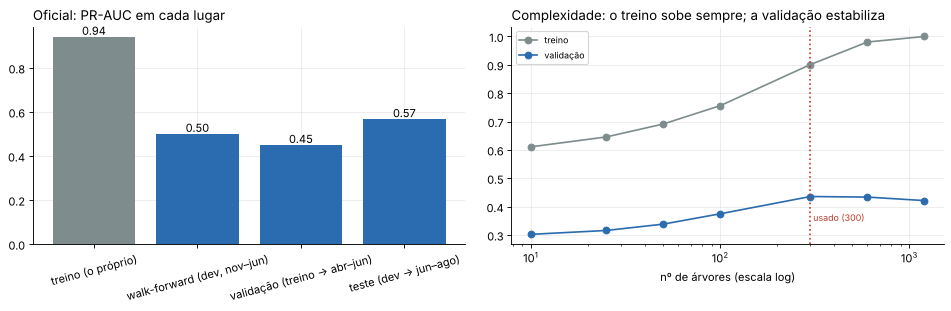

In [11]:
WF = PREV[(PREV.modelo == NOME_OFICIAL) & (PREV.parte == "walk-forward (dev)")]
gap = pd.DataFrame([
    {"onde": "treino (o próprio)", "PR-AUC": average_precision_score(TREINO.carga_alta, prever(familia(F_OF), TREINO, TREINO))},
    {"onde": "walk-forward (dev, nov–jun)", "PR-AUC": average_precision_score(WF.carga_alta, WF.p)},
    {"onde": "validação (treino → abr–jun)", "PR-AUC": average_precision_score(VALID.carga_alta, pv_ok)},
    {"onde": "teste (dev → jun–ago)", "PR-AUC": RES.loc[NOME_OFICIAL, "PR-AUC teste"]}])
gap.to_csv(PASTA / "gap_treino_wf_validacao_teste.csv", index=False)
print(gap.round(3).to_string(index=False))

cx = []
for it in [10, 25, 50, 100, 300, 600, 1200]:
    fab = HGB(it=it, **{k: v for k, v in VARIANTES["l2=5"].items()})
    mdl = fab().fit(TREINO[F_OF], TREINO.carga_alta)
    cx.append({"max_iter (nº de árvores)": it,
               "PR-AUC treino": average_precision_score(TREINO.carga_alta, mdl.predict_proba(TREINO[F_OF])[:, 1]),
               "PR-AUC validação": average_precision_score(VALID.carga_alta, mdl.predict_proba(VALID[F_OF])[:, 1])})
cx = pd.DataFrame(cx); cx.to_csv(PASTA / "curva_complexidade.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(gap.onde, gap["PR-AUC"], color=[CINZA, AZUL, AZUL, AZUL])
for i, v in enumerate(gap["PR-AUC"]):
    axes[0].text(i, v + 0.01, f"{v:.2f}", ha="center")
axes[0].tick_params(axis="x", rotation=15); axes[0].set_title("Oficial: PR-AUC em cada lugar", loc="left")
axes[1].plot(cx.iloc[:, 0], cx["PR-AUC treino"], marker="o", color=CINZA, label="treino")
axes[1].plot(cx.iloc[:, 0], cx["PR-AUC validação"], marker="o", color=AZUL, label="validação")
axes[1].axvline(300, ls=":", color=VERMELHO); axes[1].text(310, 0.35, "usado (300)", color=VERMELHO, fontsize=8)
axes[1].set_xscale("log"); axes[1].set_xlabel("nº de árvores (escala log)"); axes[1].legend(fontsize=8)
axes[1].set_title("Complexidade: o treino sobe sempre; a validação estabiliza", loc="left")
plt.tight_layout(); plt.savefig(PASTA / "graficos/01_gap_e_complexidade.png", dpi=130, bbox_inches="tight"); plt.show()
print(cx.round(3).to_string(index=False))

## 3. O teste não é uma segunda validação (slides 15 e 29)

Registro de cada vez que validação e teste foram usados no caminho do modelo oficial.

In [12]:
uso = pd.DataFrame([
    ("feature selection §6–7", "treino", "filtro e redundância", "não (descritivo)"),
    ("feature selection §8", "validação", "permutação por grupo (treino → validação)", "apoio"),
    ("feature selection §9", "dev (walk-forward)", "tirar um grupo de cada vez: minutos e PR-AUC", "sim: o conjunto de 121"),
    ("otimização (out/2026)", "dev (walk-forward)", "168 configurações; finalistas registrados", "sim: algoritmo, variantes, features"),
    ("otimização (31/out/2026)", "teste", "aberto UMA vez para os finalistas pré-registrados", "não: o escolhido estava declarado (com a condição do cestão 1)"),
    ("otimização, rodada 2", "teste", "segunda olhada só no candidato do dev (combinação grande + pequeno)", "não: ele perdeu e o oficial ficou"),
    ("seleção §6–9", "dev (walk-forward)", "algoritmos, variantes, desbalanceamento, limiar de minutos", "sim (refaz a otimização)"),
    ("seleção §10", "teste", "mesma conta da otimização, mesmos números; não-finalistas não são medidos", "não"),
    ("análise e verificação", "dev e teste", "métricas, bootstrap, calibração, segmentos, drift, critérios", "não"),
    ("rodadas da RF (out/2026)", "validação e teste", "o grupo já tinha visto este teste com a RF; ver histórico do Git", "não, para o modelo oficial"),
], columns=["etapa", "partição", "o que foi feito", "decidiu algo?"])
uso.to_csv(PASTA / "uso_validacao_e_teste.csv", index=False)
uso

,etapa,partição,o que foi feito,decidiu algo?
0,feature selection §6–7,treino,filtro e redundância,não (descritivo)
1,feature selection §8,validação,permutação por grupo (treino → validação),apoio
2,feature selection §9,dev (walk-forward),tirar um grupo de cada vez: minutos e PR-AUC,sim: o conjunto de 121
3,otimização (out/2026),dev (walk-forward),168 configurações; finalistas registrados,"sim: algoritmo, variantes, features"
4,otimização (31/out/2026),teste,aberto UMA vez para os finalistas pré-registrados,não: o escolhido estava declarado (com a condição do cestão 1)
5,"otimização, rodada 2",teste,segunda olhada só no candidato do dev (combinação grande + pequeno),não: ele perdeu e o oficial ficou
6,seleção §6–9,dev (walk-forward),"algoritmos, variantes, desbalanceamento, limiar de minutos",sim (refaz a otimização)
7,seleção §10,teste,"mesma conta da otimização, mesmos números; não-finalistas não são medidos",não
8,análise e verificação,dev e teste,"métricas, bootstrap, calibração, segmentos, drift, critérios",não
9,rodadas da RF (out/2026),validação e teste,o grupo já tinha visto este teste com a RF; ver histórico do Git,"não, para o modelo oficial"


## 4. Validação cruzada: limites e cuidados (slide 27)

A mesma receita, no dev, com quatro jeitos de dividir. Sortear linhas mistura o futuro no treino
e separa os dois cestões da mesma corrida.

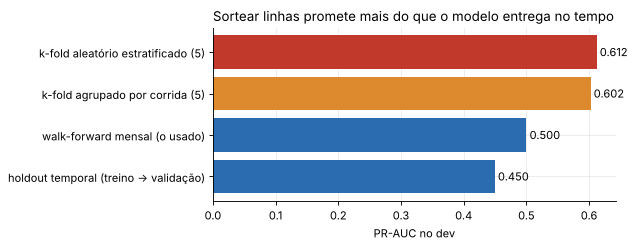

,validação,PR-AUC
0,k-fold aleatório estratificado (5),0.612
1,k-fold agrupado por corrida (5),0.602
2,walk-forward mensal (o usado),0.500
3,holdout temporal (treino → validação),0.450


In [13]:
def cv_pr(splits):
    p = pd.Series(np.nan, index=DEV.index)
    for tr, te in splits:
        p.iloc[te] = prever(familia(F_OF), DEV.iloc[tr], DEV.iloc[te])
    ok = p.notna()
    return average_precision_score(DEV.carga_alta[ok], p[ok])


tipos = pd.DataFrame([
    {"validação": "k-fold aleatório estratificado (5)", "PR-AUC": cv_pr(StratifiedKFold(5, shuffle=True, random_state=0).split(DEV, DEV.carga_alta))},
    {"validação": "k-fold agrupado por corrida (5)", "PR-AUC": cv_pr(GroupKFold(5).split(DEV, DEV.carga_alta, DEV.cd_corrida))},
    {"validação": "walk-forward mensal (o usado)", "PR-AUC": average_precision_score(WF.carga_alta, WF.p)},
    {"validação": "holdout temporal (treino → validação)", "PR-AUC": average_precision_score(VALID.carga_alta, pv_ok)}])
tipos.to_csv(PASTA / "tipos_de_validacao_cruzada.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(tipos["validação"], tipos["PR-AUC"], color=[VERMELHO, LARANJA, AZUL, AZUL])
for i, v in enumerate(tipos["PR-AUC"]):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center")
ax.invert_yaxis(); ax.set_xlabel("PR-AUC no dev")
ax.set_title("Sortear linhas promete mais do que o modelo entrega no tempo", loc="left")
plt.tight_layout(); plt.savefig(PASTA / "graficos/02_tipos_de_validacao_cruzada.png", dpi=130, bbox_inches="tight"); plt.show()
tipos.round(3)

## 5. Os dados mudaram? Data drift e concept drift (slides 33 e 34)

**PSI** (índice de estabilidade da população) das features que mais pesam, treino contra validação
e contra teste (decis do treino). Regra usual: < 0,10 estável; 0,10–0,25 atenção; > 0,25 mudou.

                      PSI validação  PSI teste  média treino  média validação  média teste
feature                                                                                   
carga_alta_c1                 0.002      0.001         0.058            0.068        0.064
h_ewm2                        0.025      0.398         0.301            0.317        0.275
gusl_t                        0.657      0.827        25.418           34.513       36.207
prop_peso_pesado              0.956      1.525         0.321            0.205        0.196
densidade_media               1.090      1.301         0.862            0.735        0.738
h_taxa_24h                    0.037      0.209         0.299            0.317        0.287
volume_c1_m3                  0.192      0.243        32.571           35.034       34.897
rendimento_medio              0.116      0.255         0.899            0.897        0.893
n_ciclos                      0.364      0.718         3.146            2.267        2.151

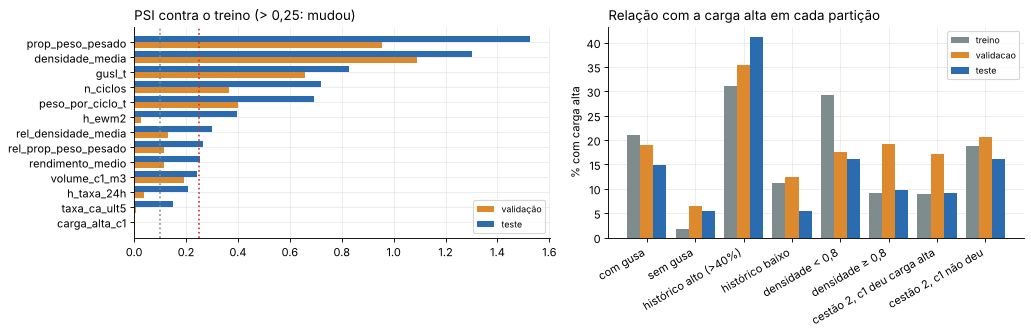

,treino,validacao,teste,n treino,n validacao,n teste
segmento,,,,,,
com gusa,0.210,0.191,0.149,1811,467,497
sem gusa,0.018,0.065,0.056,662,46,18
histórico alto (>40%),0.311,0.355,0.412,579,124,131
histórico baixo,0.112,0.123,0.055,1892,389,384
"densidade < 0,8",0.292,0.175,0.162,833,388,383
"densidade ≥ 0,8",0.091,0.192,0.098,1640,125,132
"cestão 2, c1 deu carga alta",0.090,0.171,0.091,144,35,33
"cestão 2, c1 não deu",0.189,0.207,0.160,1070,208,212


In [14]:
def psi(ref, novo, n=10):
    ref, novo = ref.dropna(), novo.dropna()
    q = np.unique(np.quantile(ref, np.linspace(0, 1, n + 1)))
    if len(q) < 3:
        cats = sorted(set(ref) | set(novo))
        r = ref.value_counts(normalize=True).reindex(cats, fill_value=0); s_ = novo.value_counts(normalize=True).reindex(cats, fill_value=0)
    else:
        q[0], q[-1] = -np.inf, np.inf
        r = pd.cut(ref, q).value_counts(normalize=True, sort=False); s_ = pd.cut(novo, q).value_counts(normalize=True, sort=False)
    r, s_ = np.clip(r.values, 1e-4, None), np.clip(s_.values, 1e-4, None)
    return float(np.sum((s_ - r) * np.log(s_ / r)))


IMP = ["carga_alta_c1", "h_ewm2", "gusl_t", "prop_peso_pesado", "densidade_media", "h_taxa_24h", "volume_c1_m3",
       "rendimento_medio", "n_ciclos", "peso_por_ciclo_t", "rel_densidade_media", "rel_prop_peso_pesado", "taxa_ca_ult5"]
drift = pd.DataFrame([{"feature": c, "PSI validação": psi(TREINO[c], VALID[c]), "PSI teste": psi(TREINO[c], TESTE[c]),
                       "média treino": TREINO[c].mean(), "média validação": VALID[c].mean(), "média teste": TESTE[c].mean()}
                      for c in IMP]).set_index("feature")
drift.to_csv(PASTA / "drift_das_features.csv")
print(drift.round(3).to_string())

# concept drift: a relação feature → alvo muda entre as partições?
rel_alvo = []
for nome, f in [("com gusa", lambda d_: d_.tem_gusl == 1), ("sem gusa", lambda d_: d_.tem_gusl == 0),
                ("histórico alto (>40%)", lambda d_: d_.taxa_ca_ult5 > 0.4), ("histórico baixo", lambda d_: d_.taxa_ca_ult5 <= 0.4),
                ("densidade < 0,8", lambda d_: d_.densidade_media < 0.8), ("densidade ≥ 0,8", lambda d_: d_.densidade_media >= 0.8),
                ("cestão 2, c1 deu carga alta", lambda d_: (d_.eh_cestao_2 == 1) & (d_.carga_alta_c1 == 1)),
                ("cestão 2, c1 não deu", lambda d_: (d_.eh_cestao_2 == 1) & (d_.carga_alta_c1 == 0))]:
    rel_alvo.append({"segmento": nome, **{p: D[(D.conjunto == p) & f(D)].carga_alta.mean() for p in ["treino", "validacao", "teste"]},
                     **{f"n {p}": int(((D.conjunto == p) & f(D)).sum()) for p in ["treino", "validacao", "teste"]}})
rel_alvo = pd.DataFrame(rel_alvo).set_index("segmento")
rel_alvo.to_csv(PASTA / "relacao_feature_alvo_por_particao.csv")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
dd_ = drift[["PSI validação", "PSI teste"]].sort_values("PSI teste")
yy = np.arange(len(dd_))
axes[0].barh(yy - 0.2, dd_["PSI validação"], 0.4, color=LARANJA, label="validação"); axes[0].barh(yy + 0.2, dd_["PSI teste"], 0.4, color=AZUL, label="teste")
axes[0].set_yticks(yy, dd_.index); axes[0].axvline(0.25, color=VERMELHO, ls=":"); axes[0].axvline(0.1, color=CINZA, ls=":")
axes[0].set_title("PSI contra o treino (> 0,25: mudou)", loc="left"); axes[0].legend(fontsize=8)
ra = rel_alvo[["treino", "validacao", "teste"]]
xs = np.arange(len(ra))
for i, (p, cor) in enumerate([("treino", CINZA), ("validacao", LARANJA), ("teste", AZUL)]):
    axes[1].bar(xs + (i - 1) * 0.27, 100 * ra[p], 0.27, color=cor, label=p)
axes[1].set_xticks(xs, ra.index, rotation=30, ha="right"); axes[1].set_ylabel("% com carga alta"); axes[1].legend(fontsize=8)
axes[1].set_title("Relação com a carga alta em cada partição", loc="left")
plt.tight_layout(); plt.savefig(PASTA / "graficos/03_drift_e_relacao_com_o_alvo.png", dpi=130, bbox_inches="tight"); plt.show()
rel_alvo.round(3)

## 5b. Backtesting walk-forward mês a mês (Guia §6.2), e re-treino mensal dentro do teste

No dev, o walk-forward já re-treina todo mês. No teste, o oficial treinou uma vez no dev. E se
ele fosse re-treinado no começo de julho e de agosto, com os dados do teste que já passaram?

                                    versão  PR-AUC teste  minutos teste
         treinado uma vez no dev (oficial)         0.567        130.800
re-treinado no início de cada mês do teste         0.590        140.033
parte     mes  PR-AUC  minutos  sem modelo  economia %
  dev 2026-01    0.51   115.07      162.95       29.39
  dev 2026-02    0.52    58.05      116.17       50.03
  dev 2026-03    0.53    62.68       99.07       36.73
  dev 2026-04    0.36   196.72      225.18       12.64
  dev 2026-05    0.47    50.27       89.45       43.80
  dev 2026-06    0.51   133.48      257.48       48.16
teste 2026-06    0.32    30.07       57.67       47.86
teste 2026-07    0.67    94.73      188.58       49.77
teste 2026-08    0.22     6.00        4.85      -23.71


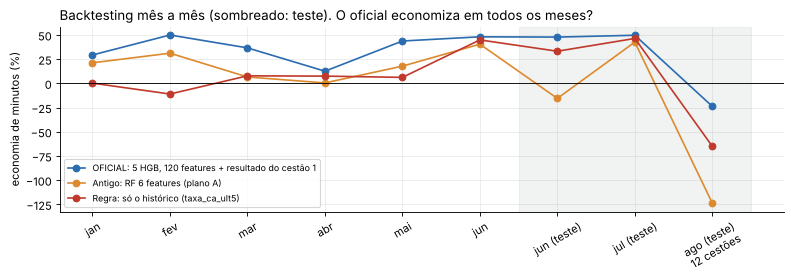

In [15]:
mes = pd.read_csv(ANA / "metricas_por_periodo.csv")
mes = mes[mes.modelo.isin([NOME_OFICIAL, NOME_RF6, NOME_REGRA])]
mes.to_csv(PASTA / "walk_forward_mensal.csv", index=False)
p_ret = pd.Series(np.nan, index=TESTE.index)
for mth in sorted(TESTE.mes.unique()):
    te = TESTE[TESTE.mes == mth]
    tr = pd.concat([DEV, TESTE[TESTE.t_ini < te.t_ini.min()]])
    p_ret[te.index] = prever(familia(F_OF), tr, te)
ret = pd.DataFrame([{"versão": "treinado uma vez no dev (oficial)", "PR-AUC teste": RES.loc[NOME_OFICIAL, "PR-AUC teste"],
                     "minutos teste": RES.loc[NOME_OFICIAL, "min perdidos teste"]},
                    {"versão": "re-treinado no início de cada mês do teste", "PR-AUC teste": average_precision_score(TESTE.carga_alta, p_ret),
                     "minutos teste": minutos(TESTE.carga_alta, TESTE.min_parada, p_ret > LIM)}])
ret.to_csv(PASTA / "teste_retreino_mensal.csv", index=False)
print(ret.round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(10, 3.6))
for m_, cor in [(NOME_OFICIAL, AZUL), (NOME_RF6, LARANJA), (NOME_REGRA, VERMELHO)]:
    q = mes[mes.modelo == m_]
    ax.plot(q.periodo, q["economia %"], marker="o", color=cor, label=m_)
n_dev = (mes[mes.modelo == NOME_OFICIAL].parte == "dev").sum()
ax.axhline(0, color="k", lw=0.8); ax.axvspan(n_dev - 0.5, (mes.modelo == NOME_OFICIAL).sum() - 0.5, color=CINZA, alpha=0.1)
ax.set_ylabel("economia de minutos (%)"); ax.legend(fontsize=8); ax.tick_params(axis="x", rotation=30)
ax.set_title("Backtesting mês a mês (sombreado: teste). O oficial economiza em todos os meses?", loc="left")
plt.tight_layout(); plt.savefig(PASTA / "graficos/04_walk_forward_mensal.png", dpi=130, bbox_inches="tight"); plt.show()
print(mes[mes.modelo == NOME_OFICIAL][["parte", "mes", "PR-AUC", "minutos", "sem modelo", "economia %"]].round(2).to_string(index=False))

## 5c. Robustez a erros de pesagem (Guia §6.2)

A balança erra. Recalculamos as features da receita dos cestões do teste com cada camada pesando
`peso × (1 + ruído)`, ruído normal de 5% e 10% (20 sorteios), e medimos quanto a chance e o
alarme mudam. A conta é a mesma do app (`app_streamlit/motor.py`, conferida contra o dataset).
As features que olham para trás (`rel_`) mudam na mesma medida da receita; histórico, gusa e
resultado do cestão 1 não dependem da balança.

In [16]:
from comum.receita import Camada, camadas_da_base, colunas_receita, recalcular as _recalcular, tabela_materiais
mats = tabela_materiais(base, F_OF)
REC = colunas_receita(mats, F_OF)


def recalcular(tab, camadas):
    return _recalcular(tab, camadas, mats, F_OF)


orig = camadas_da_base(base, TESTE.cd_corrida)
zero = recalcular(TESTE, {k: [Camada(c, p) for c, p in v] for k, v in orig.items()})
conferir("5c", "sem ruído, o recálculo reproduz as features do teste",
         np.allclose(zero[REC].fillna(-9).values.astype(float), TESTE[REC].fillna(-9).values.astype(float), atol=1e-9))
p0 = np.mean([mm_.predict_proba(TESTE[F_OF])[:, 1] for mm_ in PDEV["modelos"]], axis=0)
rob, rng = [], np.random.default_rng(1)
for sig in [0.05, 0.10]:
    for rep in range(20):
        ruid = {k: [Camada(c, p * max(1 + rng.normal(0, sig), 0.05)) for c, p in v] for k, v in orig.items()}
        X = recalcular(TESTE, ruid)
        p = np.mean([mm_.predict_proba(X[F_OF])[:, 1] for mm_ in PDEV["modelos"]], axis=0)
        rob.append({"erro da balança": f"{sig:.0%}", "sorteio": rep, "|Δ chance| médio": np.abs(p - p0).mean(),
                    "alarmes que mudam (%)": 100 * ((p > LIM) != (p0 > LIM)).mean(),
                    "PR-AUC teste": average_precision_score(TESTE.carga_alta, p), "minutos teste": minutos(TESTE.carga_alta, TESTE.min_parada, p > LIM)})
rob = pd.DataFrame(rob)
rob_res = rob.groupby("erro da balança").agg(["mean", "min", "max"]).drop(columns="sorteio")
rob.to_csv(PASTA / "robustez_erro_pesagem.csv", index=False)
print(f"Sem ruído: PR-AUC {average_precision_score(TESTE.carga_alta, p0):.3f}, {minutos(TESTE.carga_alta, TESTE.min_parada, p0 > LIM):.0f} min")
rob_res.round(3)

[OK      ] 5c sem ruído, o recálculo reproduz as features do teste 
Sem ruído: PR-AUC 0.567, 131 min


|Δ chance| médio               alarmes que mudam (%)               PR-AUC teste              minutos teste                  
                            mean    min    max                  mean    min    max         mean   min    max          mean      min      max
erro da balança                                                                                                                             
10%                        0.015  0.014  0.017                 4.087  3.107  5.437        0.560  0.54  0.581       140.164  127.033  158.000
5%                         0.009  0.008  0.010                 2.699  1.748  4.272        0.563  0.55  0.578       138.910  127.917  153.433

## 5c-bis. Sensibilidade ao corte de peso da camada (resposta da EVCOMX, out/2026)

O corte de 2.000 kg veio da EVCOMX, mas nem tudo abaixo de 2 t parece gancho vazio. Refazemos as
features da receita com os cortes de 0 (só peso zero sai), 100, 1.000 e 2.000 kg, **re-treinamos o
oficial no dev** e medimos no teste. Aproximação: as médias móveis das features `rel_` ficam as
do corte de 2.000 kg (só o valor do próprio cestão muda). Partindo do arquivo bruto, o corte de
2.000 kg não reproduz exatamente o oficial (o bruto não passa por toda a limpeza da EDA): a
comparação justa é entre as linhas desta tabela.

In [17]:
mats_b = mats.copy()
cam_b = bruto[bruto.nu_carregamento.isin([1, 2])].drop_duplicates().copy()
cam_b["peso_t"] = cam_b.qt_peso_carregamento / 1000
cam_b = cam_b[cam_b.cd_codigo_material.isin(mats_b.index)].sort_values(chave + ["nu_camada"])
cortes = []
for corte_kg in [0, 100, 1000, 2000]:
    cb = cam_b[(cam_b.qt_peso_carregamento > 0) & (cam_b.qt_peso_carregamento >= corte_kg)]
    camadas = {k: [Camada(c, p) for c, p in zip(g_.cd_codigo_material, g_.peso_t)] for k, g_ in cb.groupby(chave)}
    Dn = recalcular(D, camadas)
    dev_n = Dn[Dn.conjunto != "teste"].sort_values("t_ini").reset_index(drop=True)
    te_n = Dn[Dn.conjunto == "teste"].sort_values("t_ini").reset_index(drop=True)
    p = prever(familia(F_OF), dev_n, te_n)
    cortes.append({"corte (kg)": corte_kg, "camadas usadas": len(cb), "PR-AUC teste": average_precision_score(te_n.carga_alta, p),
                   "minutos teste (limiar do dev)": minutos(te_n.carga_alta, te_n.min_parada, p > LIM)})
cortes = pd.DataFrame(cortes); cortes.to_csv(PASTA / "sensibilidade_corte_peso.csv", index=False)
cortes.round(3)

,corte (kg),camadas usadas,PR-AUC teste,minutos teste (limiar do dev)
0,0,39777,0.569,145.400
1,100,39451,0.580,148.917
2,1000,39065,0.567,139.617
3,2000,36633,0.570,132.800


## 5d. Variação por semente (reprodutibilidade estatística)

Trocamos a semente dos 5 membros (20 sementes) e medimos validação e teste. **Resultado esperado:
nenhuma variação.** No HGB, a semente só é usada no early stopping e na subamostragem, e nenhum dos
dois está ligado aqui (menos de 10.000 cestões): o modelo é determinístico. A variação que de fato
importa é a dos **hiperparâmetros** (seleção, seção 7: as 5 variantes vão de 576 a 644 min), e é
por isso que o oficial é a média delas.

In [18]:
sem = []
for sd in range(20):
    p_sd = prever(familia(F_OF, seed=sd), DEV, TESTE)
    sem.append({"semente": sd, "PR-AUC validação": average_precision_score(VALID.carga_alta, prever(familia(F_OF, seed=sd), TREINO, VALID)),
                "PR-AUC teste": average_precision_score(TESTE.carga_alta, p_sd),
                "minutos teste": minutos(TESTE.carga_alta, TESTE.min_parada, p_sd > LIM)})
sem = pd.DataFrame(sem); sem.to_csv(PASTA / "variacao_por_semente.csv", index=False)
sem.describe().loc[["mean", "std", "min", "max"]].round(4)

,semente,PR-AUC validação,PR-AUC teste,minutos teste
mean,9.5000,0.4496,0.567,130.8
std,5.9161,0.0000,0.000,0.0
min,0.0000,0.4496,0.567,130.8
max,19.0000,0.4496,0.567,130.8


## 6. Critérios de aceitação e monitoramento (slides 34 e 35)

### 6.1 Critérios de aceitação

Definidos para **o próximo lote** (o teste atual já foi visto); aplicá-los aqui é uma ilustração.
Proposta do grupo, em minutos, a confirmar com a EVCOMX. Os parâmetros ficam no topo da célula.

In [19]:
ORC_ALARMES_DIA = 4          # quantos alarmes por dia o pátio aguenta (pergunta 4 para a EVCOMX)
an_tab = {"dev": pd.read_csv(ANA / "tabela_unica_dev.csv", index_col=0), "teste": pd.read_csv(ANA / "tabela_unica_teste.csv", index_col=0)}
fx = pd.read_csv(ANA / "faixas_de_risco.csv")
bt = boot.set_index(["modelo", "contra"])
b_rg = bt.loc[("OFICIAL: 5 HGB + cestão 1", "Regra do histórico")]; b_rf = bt.loc[("OFICIAL: 5 HGB + cestão 1", "RF 6 features (antigo)")]
dias_te = (TESTE.t_ini.max() - TESTE.t_ini.min()).days
crit = []
for parte in ["dev", "teste"]:
    t = an_tab[parte]; o = t.loc[NOME_OFICIAL]
    f_ = fx[fx.parte.str.startswith(parte)].dropna(subset=["taxa_real"])
    al_dia = (o["alarmes/100"] / 100) * (len(TESTE) / dias_te) if parte == "teste" else (o["alarmes/100"] / 100) * len(DEV[DEV.mes.isin(MESES_CUSTO)]) / 181
    crit += [
        {"critério": "C1 economiza minutos", "regra": "minutos < sem modelo, com pelo menos 20% de economia", "parte": parte,
         "valor": f"{o['economia %']:.0f}%", "passa": o["economia %"] >= 20},
        {"critério": "C2 ordena melhor que o chute", "regra": "PR-AUC ≥ 2 × taxa de carga alta", "parte": parte,
         "valor": f"{o['PR-AUC']:.2f} × {t.loc['Sem modelo (nunca alarmar)', 'PR-AUC']:.2f}", "passa": o["PR-AUC"] >= 2 * t.loc["Sem modelo (nunca alarmar)", "PR-AUC"]},
        {"critério": "C3 não perde para a regra do histórico", "regra": "minutos do oficial ≤ minutos da regra + 10%", "parte": parte,
         "valor": f"{o['minutos']:.0f} × {t.loc[NOME_REGRA, 'minutos']:.0f}", "passa": o["minutos"] <= 1.1 * t.loc[NOME_REGRA, "minutos"]},
        {"critério": "C4 faixas de risco em ordem", "regra": "taxa real cresce com a faixa de chance", "parte": parte,
         "valor": " < ".join(f"{v:.0%}" for v in f_.taxa_real), "passa": bool(np.all(np.diff(f_.taxa_real.values) > 0))},
        {"critério": "C5 cabe no pátio", "regra": f"≤ {ORC_ALARMES_DIA} alarmes por dia, em média", "parte": parte,
         "valor": f"{al_dia:.1f}/dia", "passa": al_dia <= ORC_ALARMES_DIA}]
crit.append({"critério": "C6 (desejável) supera a RF antiga além do ruído", "regra": "IC 90% da diferença de minutos < 0 (bootstrap por dia)",
             "parte": "teste", "valor": f"{b_rf['dif minutos']:+.0f} min, IC90 {b_rf['IC90 minutos']}", "passa": ic(b_rf["IC90 minutos"])[1] < 0})
crit.append({"critério": "C7 (desejável) supera a regra do histórico além do ruído", "regra": "IC 90% da diferença de minutos < 0",
             "parte": "teste", "valor": f"{b_rg['dif minutos']:+.0f} min, IC90 {b_rg['IC90 minutos']}",
             "passa": ic(b_rg["IC90 minutos"])[1] < 0})
crit = pd.DataFrame(crit); crit.to_csv(PASTA / "criterios_aceitacao.csv", index=False)
crit

,critério,regra,parte,valor,passa
0,C1 economiza minutos,"minutos < sem modelo, com pelo menos 20% de economia",dev,35%,True
1,C2 ordena melhor que o chute,PR-AUC ≥ 2 × taxa de carga alta,dev,0.50 × 0.16,True
2,C3 não perde para a regra do histórico,minutos do oficial ≤ minutos da regra + 10%,dev,616 × 816,True
3,C4 faixas de risco em ordem,taxa real cresce com a faixa de chance,dev,3% < 13% < 13% < 26% < 55%,False
4,C5 cabe no pátio,"≤ 4 alarmes por dia, em média",dev,2.3/dia,True
5,C1 economiza minutos,"minutos < sem modelo, com pelo menos 20% de economia",teste,48%,True
6,C2 ordena melhor que o chute,PR-AUC ≥ 2 × taxa de carga alta,teste,0.57 × 0.15,True
7,C3 não perde para a regra do histórico,minutos do oficial ≤ minutos da regra + 10%,teste,131 × 147,True
8,C4 faixas de risco em ordem,taxa real cresce com a faixa de chance,teste,3% < 4% < 10% < 29% < 59%,True
9,C5 cabe no pátio,"≤ 4 alarmes por dia, em média",teste,3.7/dia,True


### 6.2 Monitoramento depois da implantação (slide 34)

Simulação: o oficial treinado no dev operando no teste, em janelas de ~10 dias (o teste tem 40).
Gatilhos propostos: **G1** PSI > 0,25 em alguma feature da receita ou da gusa, contra os **últimos
60 dias** antes da operação (o histórico do forno fica de fora: ele oscila por natureza em janelas
curtas); **G2** alarmes/100 fora de ±15 do esperado no dev; **G3** economia de minutos < 20%;
**G4** perde para a regra do histórico.

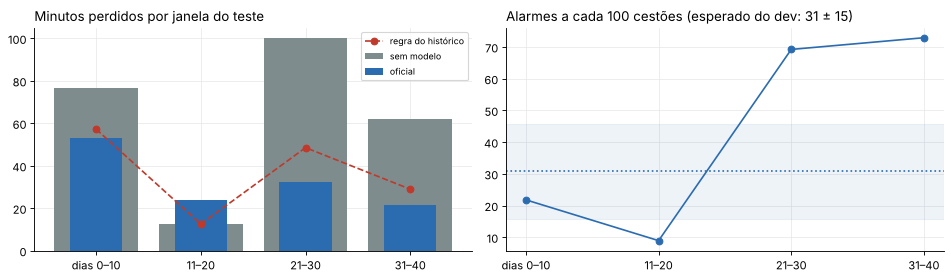

,janela,cestões,cargas altas,PSI máx,feature,alarmes/100,minutos,sem modelo,economia %,minutos da regra,gatilhos
0,dias 0–10,188,20,0.34,gusl_t,21.81,52.97,76.47,30.73,57.28,G1
1,11–20,201,5,0.55,rendimento_medio,8.96,23.93,12.58,-90.20,12.58,"G1, G2, G3, G4"
2,21–30,78,33,0.95,gusl_t,69.23,32.18,100.12,67.85,48.57,"G1, G2"
3,31–40,48,17,1.17,gusl_t,72.92,21.72,61.93,64.94,29.00,"G1, G2"


In [20]:
WFd = PREV[(PREV.modelo == NOME_OFICIAL) & (PREV.parte == "walk-forward (dev)")]
al_esp = 100 * (WFd[WFd.mes.isin(MESES_CUSTO)].p > LIM).mean()
TT = TESTE.assign(p=pt.p.values)
TT["janela"] = pd.cut((TT.t_ini - TT.t_ini.min()).dt.days, [-1, 10, 20, 30, 41], labels=["dias 0–10", "11–20", "21–30", "31–40"])
mon = []
MON = ["prop_peso_pesado", "densidade_media", "gusl_t", "n_ciclos", "peso_por_ciclo_t", "rendimento_medio",
       "volume_c1_m3", "rel_densidade_media", "rel_prop_peso_pesado"]
REF60 = DEV[DEV.t_ini >= DEV.t_ini.max() - pd.Timedelta(days=60)]
for j, g_ in TT.groupby("janela", observed=True):
    psimax = max((psi(REF60[c], g_[c]), c) for c in MON if g_[c].nunique() > 1)
    al = 100 * (g_.p > LIM).mean(); mi = minutos(g_.carga_alta, g_.min_parada, g_.p > LIM)
    mr = minutos(g_.carga_alta, g_.min_parada, g_.taxa_ca_ult5.fillna(0) > RES.loc[NOME_REGRA, "limiar"])
    eco = 100 * (1 - mi / g_.min_parada.sum())
    gat = [n for n, cond in [("G1", psimax[0] > 0.25), ("G2", abs(al - al_esp) > 15), ("G3", eco < 20), ("G4", mi > mr)] if cond]
    mon.append({"janela": j, "cestões": len(g_), "cargas altas": int(g_.carga_alta.sum()), "PSI máx": round(psimax[0], 2),
                "feature": psimax[1], "alarmes/100": al, "minutos": mi, "sem modelo": g_.min_parada.sum(), "economia %": eco,
                "minutos da regra": mr, "gatilhos": ", ".join(gat) or "—"})
mon = pd.DataFrame(mon); mon.to_csv(PASTA / "monitoramento_simulado.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].bar(mon.janela.astype(str), mon["sem modelo"], color=CINZA, label="sem modelo")
axes[0].bar(mon.janela.astype(str), mon.minutos, color=AZUL, label="oficial", width=0.5)
axes[0].plot(mon.janela.astype(str), mon["minutos da regra"], "o--", color=VERMELHO, label="regra do histórico")
axes[0].set_title("Minutos perdidos por janela do teste", loc="left"); axes[0].legend(fontsize=8)
axes[1].plot(mon.janela.astype(str), mon["alarmes/100"], marker="o", color=AZUL)
axes[1].axhspan(al_esp - 15, al_esp + 15, color=AZUL, alpha=0.08); axes[1].axhline(al_esp, color=AZUL, ls=":")
axes[1].set_title(f"Alarmes a cada 100 cestões (esperado do dev: {al_esp:.0f} ± 15)", loc="left")
plt.tight_layout(); plt.savefig(PASTA / "graficos/05_monitoramento_simulado.png", dpi=130, bbox_inches="tight"); plt.show()
mon.round(2)

### 6.3 Validação de domínio: o modelo faz sentido físico? (Guia de Modelagem §6.3)

Mudamos uma coisa de cada vez nos cestões do teste e olhamos para onde a chance anda. A troca
de material é feita "como no pátio": **5 t de leve viram 5 t de pesado** (a receita é recalculada
inteira, como no app). Esperado pela física e pela operação:

In [21]:
ESPERADO = {"+5 t de pesado no lugar de 5 t de leve": "−", "+1 corrida com carga alta no histórico recente": "+",
            "com gusa líquida (+34 t) × sem": "+", "cestão 1 deu carga alta (só cestão 2)": "−"}
p_base = p0
dom = []
# 1) troca leve -> pesado (5 t), recalculando a receita
troca = {}
for k, v in orig.items():
    cams = [list(x) for x in v]; resto = 5.0
    for x in cams:
        if resto <= 0:
            break
        if mats.loc[x[0], "classe"] == "Leve":
            tira = min(resto, x[1] - 2.0) if x[1] > 2.0 else 0; x[1] -= tira; resto -= tira
    tirado = 5.0 - resto
    troca[k] = [Camada(c, p) for c, p in cams] + ([Camada("GUSS", tirado)] if tirado > 0 else [])
X = recalcular(TESTE, troca)
dom.append(("+5 t de pesado no lugar de 5 t de leve", np.mean([mm_.predict_proba(X[F_OF])[:, 1] for mm_ in PDEV["modelos"]], axis=0) - p_base))
# 2) histórico: uma corrida a mais com carga alta nas janelas recentes
X = TESTE.copy()
for c, n in [("h_taxa3", 3), ("h_taxa5", 5), ("taxa_ca_ult5", 5), ("h_taxa10", 10), ("taxa_ca_ult10", 10), ("h_taxa20", 20), ("taxa_ca_ult20", 20), ("h_taxa50", 50)]:
    X[c] = np.minimum(X[c] + 1 / n, 1)
X["h_ult1"] = 1; X["h_ewm2"] = np.minimum(X.h_ewm2 + 0.3, 1)
dom.append(("+1 corrida com carga alta no histórico recente", np.mean([mm_.predict_proba(X[F_OF])[:, 1] for mm_ in PDEV["modelos"]], axis=0) - p_base))
# 3) gusa
Xg, Xs = TESTE.copy(), TESTE.copy(); Xg["gusl_t"], Xg["tem_gusl"] = 34.3, 1; Xs["gusl_t"], Xs["tem_gusl"] = 0.0, 0
dom.append(("com gusa líquida (+34 t) × sem", np.mean([mm_.predict_proba(Xg[F_OF])[:, 1] - mm_.predict_proba(Xs[F_OF])[:, 1] for mm_ in PDEV["modelos"]], axis=0)))
# 4) cestão 1
X1, X0 = TESTE.copy(), TESTE.copy(); X1["carga_alta_c1"], X0["carga_alta_c1"] = 1, 0
eh2 = (TESTE.eh_cestao_2 == 1).values
dom.append(("cestão 1 deu carga alta (só cestão 2)", np.mean([mm_.predict_proba(X1[F_OF])[:, 1] - mm_.predict_proba(X0[F_OF])[:, 1] for mm_ in PDEV["modelos"]], axis=0)[eh2]))
vd = pd.DataFrame([{"mudança": n, "esperado": ESPERADO[n], "Δ chance média": d_.mean(), "% dos cestões no sentido esperado":
                    100 * ((d_ < 0) if ESPERADO[n] == "−" else (d_ > 0)).mean()} for n, d_ in dom])
vd["bate com a física?"] = np.where(np.sign(vd["Δ chance média"]) == vd.esperado.map({"+": 1, "−": -1}), "sim", "NÃO")
vd.to_csv(PASTA / "validacao_dominio.csv", index=False)
vd.round(3)

,mudança,esperado,Δ chance média,% dos cestões no sentido esperado,bate com a física?
0,+5 t de pesado no lugar de 5 t de leve,−,-0.037,75.728,sim
1,+1 corrida com carga alta no histórico recente,+,0.024,73.398,sim
2,com gusa líquida (+34 t) × sem,+,0.102,99.806,sim
3,cestão 1 deu carga alta (só cestão 2),−,-0.151,96.327,sim


### 6.4 Validação de negócio: vale a pena? (Guia de Modelagem §6.4)

"Minutos evitados" supõe que **todo alarme certo evita a parada inteira** (é o teto do ganho).
E se o reajuste evitar só parte da parada? E se o alarme certo também custar 1 min? Teste
(40 dias), por 30 dias.

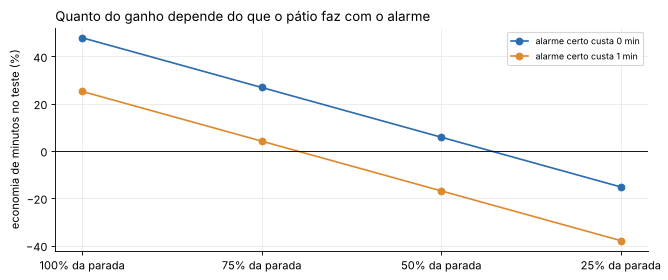

,o alarme certo evita,alarme certo custa,min perdidos / 30 dias,sem modelo / 30 dias,economia %
0,100% da parada,0 min,98.1,188.3,47.9
1,100% da parada,1 min,140.8,188.3,25.2
2,75% da parada,0 min,137.7,188.3,26.9
3,75% da parada,1 min,180.5,188.3,4.2
4,50% da parada,0 min,177.3,188.3,5.8
5,50% da parada,1 min,220.1,188.3,-16.9
6,25% da parada,0 min,217.0,188.3,-15.2
7,25% da parada,1 min,259.7,188.3,-37.9


In [22]:
neg = []
yb = TESTE.carga_alta.values.astype(bool); al_ = pt.p.values > LIM; dur = TESTE.min_parada.values
for efic in [1.0, 0.75, 0.5, 0.25]:
    for c_tp in [0.0, 1.0]:
        perdido = dur[yb & ~al_].sum() + (1 - efic) * dur[yb & al_].sum() + C_FP * (al_ & ~yb).sum() + c_tp * (al_ & yb).sum()
        neg.append({"o alarme certo evita": f"{efic:.0%} da parada", "alarme certo custa": f"{c_tp:.0f} min",
                    "min perdidos / 30 dias": perdido * 30 / dias_te, "sem modelo / 30 dias": SEM_TESTE * 30 / dias_te,
                    "economia %": 100 * (1 - perdido / SEM_TESTE)})
neg = pd.DataFrame(neg); neg.to_csv(PASTA / "validacao_negocio.csv", index=False)
fig, ax = plt.subplots(figsize=(8.5, 3.6))
for c_tp, cor in [("0 min", AZUL), ("1 min", LARANJA)]:
    q = neg[neg["alarme certo custa"] == c_tp]
    ax.plot(q["o alarme certo evita"], q["economia %"], marker="o", color=cor, label=f"alarme certo custa {c_tp}")
ax.axhline(0, color="k", lw=0.8); ax.set_ylabel("economia de minutos no teste (%)"); ax.legend(fontsize=8)
ax.set_title("Quanto do ganho depende do que o pátio faz com o alarme", loc="left")
plt.tight_layout(); plt.savefig(PASTA / "graficos/06_validacao_de_negocio.png", dpi=130, bbox_inches="tight"); plt.show()
neg.round(1)

## 7. Registro do experimento (slide 30)

In [23]:
def h(p):
    return hashlib.sha256(open(p, "rb").read()).hexdigest()[:16]


registro = {
    "modelo": "OFICIAL: média das probabilidades de 5 HistGradientBoostingClassifier, sem pesos de classe",
    "features": {"n": len(F_OF), "arquivo": "src/feature_selection/features_finais.json", "grupos": {k: len(v) for k, v in GRUPOS.items()}},
    "variantes": VARIANTES, "semente": 42, "limiar_dev": LIM, "limiar_uso_TP0": PAC["com_cestao1"]["limiar_minutos_TP0"],
    "split": "70/15/15 temporal por corrida; dev = treino + validação; walk-forward mensal nov/25–jun/26",
    "regua": "minutos perdidos: FN = duração da parada; FP = 1 min; TP = 0 (cenário TP=1 também reportado)",
    "resultado_teste": {"PR-AUC": RES.loc[NOME_OFICIAL, "PR-AUC teste"], "minutos": RES.loc[NOME_OFICIAL, "min perdidos teste"],
                        "sem_modelo": SEM_TESTE, "economia_%": RES.loc[NOME_OFICIAL, "economia teste %"]},
    "hash_dados": {p: h(RAIZ / p) for p in ["original_dataset/infos_camadas.csv", "original_dataset/VariavelResposta.csv",
                                            "src/EDA/base.csv", "src/feature_selection/dataset_modelagem_fs.csv"]},
    "versoes": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                "scikit-learn": sklearn.__version__, "scipy": scipy.__version__},
    "antigo": "RF 6 features (plano A): ver histórico do Git",
}
json.dump(registro, open(PASTA / "registro_experimento.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1, default=float)
open(PASTA / "requirements_rodada.txt", "w").write("\n".join(f"{k}=={v}" for k, v in registro["versoes"].items() if k != "python") + "\n")
pd.DataFrame(CHECK).to_csv(PASTA / "checklist_verificacao.csv", index=False)
print(pd.DataFrame(CHECK).status.value_counts().to_string())

status
OK          26
RESSALVA     3


## 8. Conclusão: podemos confiar no modelo? (slides 37 e 38)

In [24]:
ck = pd.DataFrame(CHECK).status.value_counts()
print(f"""Verificação: {len(CHECK)} conferências — {ck.get('OK', 0)} OK, {ck.get('RESSALVA', 0)} com ressalva, {ck.get('FALHA', 0)} falhas.
Gap: treino {gap['PR-AUC'][0]:.2f} → walk-forward {gap['PR-AUC'][1]:.2f} → validação {gap['PR-AUC'][2]:.2f} → teste {gap['PR-AUC'][3]:.2f}.
Sementes: PR-AUC no teste de {sem['PR-AUC teste'].min():.3f} a {sem['PR-AUC teste'].max():.3f}; minutos de {sem['minutos teste'].min():.0f} a {sem['minutos teste'].max():.0f}.
Balança com erro de 10%: {rob[rob['erro da balança'] == '10%']['alarmes que mudam (%)'].mean():.1f}% dos alarmes mudam.
Corte de peso: PR-AUC no teste de {cortes['PR-AUC teste'].min():.3f} a {cortes['PR-AUC teste'].max():.3f} entre 0 e 2.000 kg.
Domínio: {(vd['bate com a física?'] == 'sim').sum()} de {len(vd)} sentidos batem com a física.
Critérios mínimos (C1–C5) no teste: {'passam' if crit[(crit.parte == 'teste') & crit['critério'].str.match('C[1-5] ')].passa.all() else 'NÃO passam todos'}.""")

Verificação: 29 conferências — 26 OK, 3 com ressalva, 0 falhas.
Gap: treino 0.94 → walk-forward 0.50 → validação 0.45 → teste 0.57.
Sementes: PR-AUC no teste de 0.567 a 0.567; minutos de 131 a 131.
Balança com erro de 10%: 4.1% dos alarmes mudam.
Corte de peso: PR-AUC no teste de 0.567 a 0.580 entre 0 e 2.000 kg.
Domínio: 4 de 4 sentidos batem com a física.
Critérios mínimos (C1–C5) no teste: passam.
